### Explainable AI (SHAP) & Customer Success Action Cards
From previous notebook we have our trained LightGBM booster (models/lgbm_churn_model.txt) and cost-calibrated threshold (models/threshold_config.json). This notebook translates black-box predictions into transparent business diagnostics.

Here we will perform below:

* **Global Explainability (Macro):** Compute exact Shapley values via shap.TreeExplainer and visualize the top system-wide churn drivers with a Beeswarm summary plot.
* **Feature Interaction Analysis:** Plot a SHAP dependence curve showing how tenure and MonthlyCharges interact to create early churn risk.
* **Local Explainability (Micro):** Generate Waterfall plots for individual accounts to see the exact push-and-pull of features from the baseline log-odds to the final prediction.
* **Automated Action Card Generator:** Build a Python diagnostic function that maps a customer's top negative SHAP drivers into plain-English recommendations for Customer Success managers.

### Load Model Artifacts, Test Data & Initialize (TreeExplainer)

In [1]:
import json
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap

shap.initjs()

# 1. Load processed test data and feature names
X_test = np.load("../data/processed/X_test.npy")
y_test = np.load("../data/processed/y_test.npy")

with open("../models/feature_names.json", "r") as f:
    feature_names = json.load(f)

with open("../models/threshold_config.json", "r") as f:
    threshold_config = json.load(f)

optimal_threshold = threshold_config["optimal_threshold"]

# 2. Load native LightGBM booster
booster = lgb.Booster(model_file="../models/lgbm_churn_model.txt")

# 3. Initialize SHAP TreeExplainer and compute values for X_test
explainer = shap.TreeExplainer(booster)
shap_values = explainer(X_test)
shap_values.feature_names = feature_names

print(f"Computed SHAP matrix shape: {shap_values.values.shape}")
print(f"Loaded optimal business threshold: {optimal_threshold:.2f}({optimal_threshold})")

Computed SHAP matrix shape: (1409, 34)
Loaded optimal business threshold: 0.10(0.095)


### Global Explainability — Macro Churn Drivers (Beeswarm & Bar Plot)

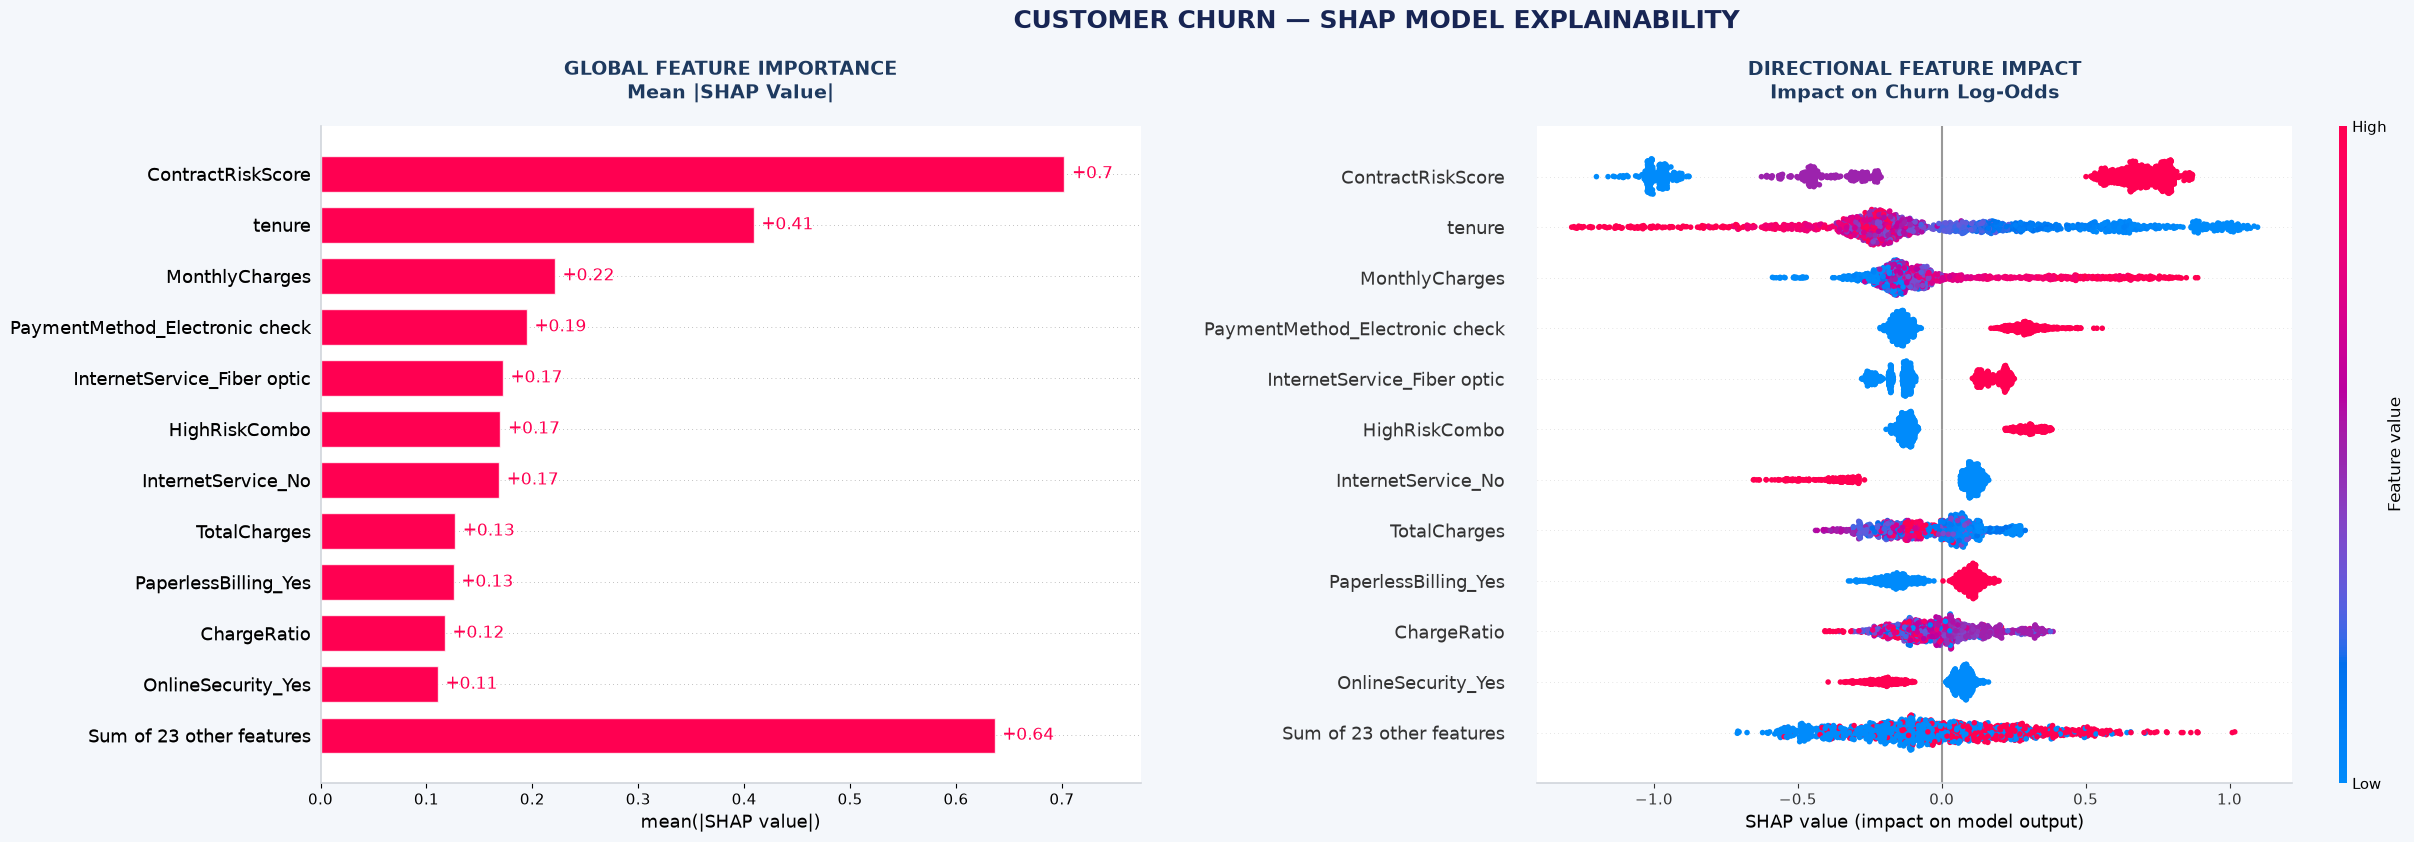

In [2]:
# --------------------------------------------------
# Figure Setup
# --------------------------------------------------
fig, axes = plt.subplots(
    1, 2,
    figsize=(24, 9),
    gridspec_kw={
        "width_ratios": [1, 1.15],
        "wspace": 0.45
    },
    facecolor="#F4F7FB"
)

# Style individual plot backgrounds
for ax in axes:
    ax.set_facecolor("#FFFFFF")
    for spine in ax.spines.values():
        spine.set_color("#D1D5DB")
        spine.set_linewidth(1.2)

# --------------------------------------------------
# 1. Global Feature Importance (Mean |SHAP|)
# --------------------------------------------------
shap.plots.bar(
    shap_values,
    max_display=12,
    ax=axes[0],
    show=False
)

axes[0].set_title(
    "GLOBAL FEATURE IMPORTANCE\nMean |SHAP Value|",
    fontsize=14,
    fontweight="bold",
    color="#1E3A5F",
    pad=20
)

# --------------------------------------------------
# 2. Directional Beeswarm Plot
# --------------------------------------------------
shap.plots.beeswarm(
    shap_values,
    max_display=12,
    ax=axes[1],
    plot_size=None,  # Fix: prevents axis and plot_size conflict
    show=False
)

axes[1].set_title(
    "DIRECTIONAL FEATURE IMPACT\nImpact on Churn Log-Odds",
    fontsize=14,
    fontweight="bold",
    color="#1E3A5F",
    pad=20
)

# --------------------------------------------------
# Main Title
# --------------------------------------------------
fig.suptitle(
    "CUSTOMER CHURN — SHAP MODEL EXPLAINABILITY",
    fontsize=18,
    fontweight="bold",
    color="#172554",
    y=0.98
)

# --------------------------------------------------
# Layout
# --------------------------------------------------
fig.subplots_adjust(
    left=0.06,
    right=0.96,
    top=0.85,
    bottom=0.12,
    wspace=0.45
)

plt.show()

These plots look super clean and tell a crystal-clear business story. Here are the key observations you can document directly in Notebook 04's Markdown cell (and highlight in interviews):

### 1. Engineered Features Validated as Top Drivers

* **`ContractRiskScore` (+0.70 Mean |SHAP|)** is the single strongest predictor across the entire model—nearly double the impact of the second feature (`tenure` at `+0.41`). On the beeswarm plot, you can see three distinct vertical clusters:
* **Red dots (`2` = Month-to-month):** Pushes churn log-odds strongly positive (`+0.5` to `+0.9`).
* **Purple dots (`1` = 1-year):** Moderately protective (`-0.25` to `-0.6`).
* **Blue dots (`0` = 2-year):** Strongly protective (`-0.8` to `-1.2`).


* **`HighRiskCombo` (+0.17)** and **`ChargeRatio` (+0.12)** both broke into the top 10 global features out of 34 total features, proving your domain feature engineering added genuine predictive lift beyond the raw columns.

### 2. Clear Directional Risk Drivers (Pushing Churn UP)

* **Early Tenure (`tenure` blue dots):** New customers (low tenure) stretch far to the right (`+0.3` to `+1.1` log-odds), whereas long-tenured accounts (red dots) pull left down to `-1.3`.
* **Price Friction (`MonthlyCharges` red dots):** High monthly bills push risk upward (`+0.1` to `+0.9`), showing sensitivity to plan cost.
* **Billing & Service Friction:** Using **Electronic check** (`+0.19`), having **Fiber optic internet** (`+0.17`), and using **Paperless billing** (`+0.13`) all consistently shift predictions toward churn (clean red clusters on the right of `0.0`).

### 3. Strong Retention Anchors (Pulling Churn DOWN)

* **No Internet Service (`InternetService_No` red dots):** Customers on phone-only plans (`-0.3` to `-0.7`) rarely churn compared to internet subscribers.
* **Product Stickiness (`OnlineSecurity_Yes` red dots):** Accounts subscribed to Online Security (`+0.11`) show a clear protective pull to the left (`-0.15` to `-0.4`), confirming that multi-product adoption reduces churn.

### Non-Linear Feature Interaction (tenure vs. MonthlyCharges)
Inspect how tenure length changes the impact of monthly pricing friction:

findfont: Failed to find font weight semibold, now using 700.


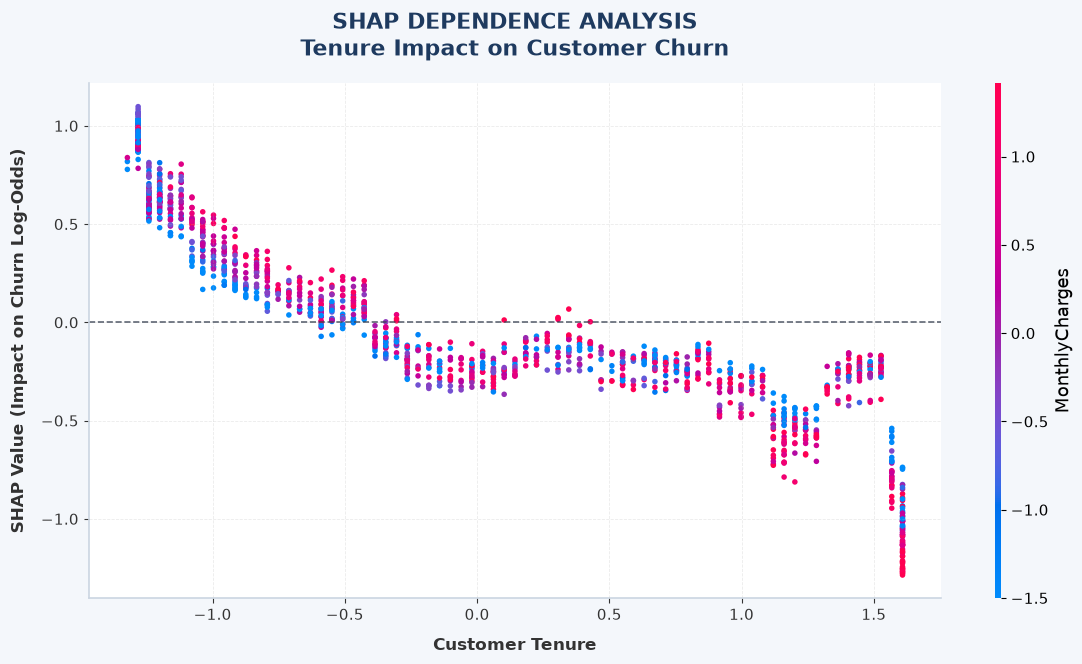

In [3]:


# --------------------------------------------------
# SHAP Dependence Plot: Tenure vs MonthlyCharges
# --------------------------------------------------
fig, ax = plt.subplots(
    figsize=(12, 7),
    facecolor="#F4F7FB"
)

ax.set_facecolor("#FFFFFF")

# SHAP dependence plot
shap.dependence_plot(
    "tenure",
    shap_values.values,
    X_test,
    feature_names=feature_names,
    interaction_index="MonthlyCharges",
    ax=ax,
    show=False,
)

# --------------------------------------------------
# Styling
# --------------------------------------------------
ax.set_title(
    "SHAP DEPENDENCE ANALYSIS\nTenure Impact on Customer Churn",
    fontsize=16,
    fontweight="bold",
    color="#1E3A5F",
    pad=20
)

ax.set_xlabel(
    "Customer Tenure",
    fontsize=12,
    fontweight="semibold",
    labelpad=10
)

ax.set_ylabel(
    "SHAP Value (Impact on Churn Log-Odds)",
    fontsize=12,
    fontweight="semibold",
    labelpad=10
)

ax.axhline(
    y=0,
    color="#374151",
    linestyle="--",
    linewidth=1.2,
    alpha=0.8
)

ax.grid(
    True,
    linestyle="--",
    linewidth=0.6,
    alpha=0.25
)

# Subtle border
for spine in ax.spines.values():
    spine.set_color("#CBD5E1")
    spine.set_linewidth(1.2)

# Layout
plt.tight_layout(pad=2.0)
plt.show()

This dependence plot reveals a clear non-linear tipping point and a distinct pricing interaction across the customer lifecycle:

* **The Zero-Crossing Tipping Point (`x ≈ -0.45` standardized tenure):**
  * **Left of `-0.45` (Early-stage accounts, roughly months 0–20):** SHAP values sit above `0.0` (up to `+1.1` log-odds), meaning short tenure actively accelerates churn risk.
  * **Right of `-0.45` (Established accounts):** SHAP values drop below `0.0`, shifting tenure into a protective anchor.


* **Price Friction Interaction (`MonthlyCharges` vertical spread):**
  * **In early tenure (`x < -0.45`):** Red dots (high `MonthlyCharges`) sit consistently *above* blue dots (low `MonthlyCharges`) at the exact same tenure—high-paying new customers churn faster due to early sticker shock or onboarding friction.
  * **In late tenure (`x > 1.0`, ~60+ months):** The interaction inverts—red dots drop furthest down (to `-1.3` log-odds), meaning high-paying veteran customers who survive past the early cliff become deeply entrenched and least likely to leave.





*(Note: Because `X_test` passed through `StandardScaler`, the x-axis displays z-scores where `0.0` equals the mean tenure of ~32 months and `1.0` standard deviation is ~24.5 months.)*

---
### Local Explainability — Single-Account Waterfall Diagnosis
Inspect a high-risk account from the test partition to see why the model flagged it:

Inspecting Test Account Index: 1
Predicted Churn Probability  : 90.80%
Actual Ground Truth Churn    : False


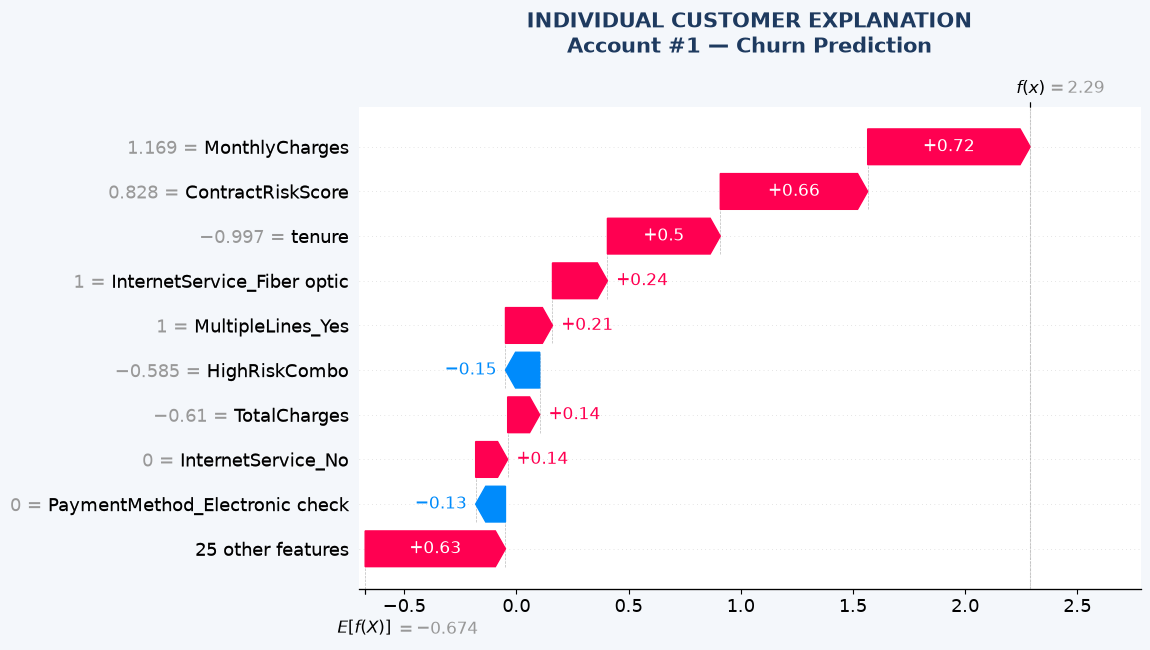

In [4]:
# Predict probabilities on X_test
y_test_probs = booster.predict(X_test)

# Pick a high-probability churn account
high_risk_indices = np.where(y_test_probs >= 0.75)[0]
sample_idx = int(high_risk_indices[0])

print(f"Inspecting Test Account Index: {sample_idx}")
print(f"Predicted Churn Probability  : {y_test_probs[sample_idx]:.2%}")
print(f"Actual Ground Truth Churn    : {bool(y_test[sample_idx])}")

# Render Waterfall Plot for this specific account
# --------------------------------------------------
# SHAP Waterfall Plot — Individual Customer
# --------------------------------------------------
shap.plots.waterfall(
    shap_values[sample_idx],
    max_display=10,
    show=False
)

# Get SHAP-generated figure and axes
fig = plt.gcf()
ax = plt.gca()

# Figure styling
fig.set_size_inches(12, 7)
fig.set_facecolor("#F4F7FB")
ax.set_facecolor("#FFFFFF")

# Title
ax.set_title(
    f"INDIVIDUAL CUSTOMER EXPLANATION\nAccount #{sample_idx} — Churn Prediction",
    fontsize=15,
    fontweight="bold",
    color="#1E3A5F",
    pad=20
)

# Subtle grid
ax.grid(axis="x", linestyle="--", alpha=0.2)

# Layout
plt.tight_layout(pad=2.5)
plt.show()

This waterfall plot walks through Account #1's exact prediction math from baseline to final score:

* **Baseline (`E[f(X)] = -0.674`):** Starting average log-odds across the dataset before looking at Account #1's features.
* **Top Positive Churn Drivers (Red bars pushing risk right):**
  1. **`MonthlyCharges` (`+0.72`):** Standardized value `1.169` (~$100/month)—high bill shock is the #1 driver for this specific account.
  2. **`ContractRiskScore` (`+0.66`):** Standardized value `0.828` (Month-to-month contract)—zero lock-in commitment.
  3. **`tenure` (`+0.50`):** Standardized value `-0.997` (~8 months)—still inside the vulnerable first-year window.
  4. **`InternetService_Fiber optic` (`+0.24`)** & **`MultipleLines_Yes` (`+0.21`)**: Add secondary service-tier friction.

* **Protective Factors (Blue bars pulling risk left):**
  * **`HighRiskCombo` (`-0.15`):** Standardized `-0.585` (`0` = not in the high-risk triad, likely because they already have Tech Support).
  * **`PaymentMethod_Electronic check` (`-0.13`):** Value `0` (using an automatic or non-electronic-check payment method).

* **Final Prediction (`f(x) = 2.29`):** Summing all SHAP bars (`-0.674 + 2.964 = 2.29` log-odds), which converts via sigmoid $\frac{1}{1 + e^{-2.29}}$ to a **90.8% churn probability**.



---
### Automated Customer Success Action Card Generator
Turn raw SHAP values into a structured JSON/dictionary payload ready for our FastAPI service:

In [5]:
INTERVENTION_PLAYBOOK = {
    "ContractRiskScore": "Offer a 15% discount to migrate from Month-to-Month to a 1-Year contract.",
    "Contract_One year": "Reinforce annual renewal perks 60 days prior to contract expiration.",
    "Contract_Two year": "Maintain standard executive check-in cadence.",
    "tenure": "Enroll account in 90-day high-touch onboarding success track.",
    "HighRiskCombo": "Assign priority technical onboarding specialist + complimentary Tech Support trial.",
    "TechSupport_Yes": "Highlight existing support utilization in quarterly business review.",
    "InternetService_Fiber optic": "Audit line stability/latency and offer bandwidth optimization check.",
    "MonthlyCharges": "Review plan tier utilization to prevent bill shock or offer bundle credit.",
    "ChargeRatio": "Audit recent billing spikes or overage charges with account admin.",
    "OnlineSecurity_Yes": "Bundle security suite add-on to increase product stickiness.",
    "PaymentMethod_Electronic check": "Incentivize switch to Auto-Pay (Credit Card/Bank Transfer) with a $10 credit.",
}


def generate_account_action_card(account_idx: int) -> dict:
    prob = float(y_test_probs[account_idx])
    row_shap = shap_values.values[account_idx]

    # Sort features pushing toward churn (positive SHAP values)
    positive_risk_indices = np.argsort(row_shap)[::-1]
    top_drivers = []
    recommendations = []

    for idx in positive_risk_indices:
        impact = float(row_shap[idx])
        if impact <= 0 or len(top_drivers) >= 3:
            continue

        feat_name = feature_names[idx]
        top_drivers.append({
            "feature": feat_name,
            "shap_impact": round(impact, 4),
        })

        # Match playbook action
        action = INTERVENTION_PLAYBOOK.get(
            feat_name,
            f"Schedule Customer Success review focusing on '{feat_name}' configuration.",
        )
        if action not in recommendations:
            recommendations.append(action)

    risk_tier = (
        "Critical" if prob >= 0.70
        else "High" if prob >= optimal_threshold
        else "Low"
    )

    return {
        "test_account_index": account_idx,
        "churn_probability": round(prob, 4),
        "decision_threshold": optimal_threshold,
        "risk_tier": risk_tier,
        "flag_for_outreach": prob >= optimal_threshold,
        "top_churn_drivers": top_drivers,
        "recommended_actions": recommendations,
    }


# Test on our high-risk account
action_card = generate_account_action_card(sample_idx)
print(json.dumps(action_card, indent=2))

{
  "test_account_index": 1,
  "churn_probability": 0.908,
  "decision_threshold": 0.095,
  "risk_tier": "Critical",
  "flag_for_outreach": true,
  "top_churn_drivers": [
    {
      "feature": "MonthlyCharges",
      "shap_impact": 0.7242
    },
    {
      "feature": "ContractRiskScore",
      "shap_impact": 0.657
    },
    {
      "feature": "tenure",
      "shap_impact": 0.503
    }
  ],
  "recommended_actions": [
    "Review plan tier utilization to prevent bill shock or offer bundle credit.",
    "Offer a 15% discount to migrate from Month-to-Month to a 1-Year contract.",
    "Enroll account in 90-day high-touch onboarding success track."
  ]
}


This action card output matches the waterfall plot down to the third decimal place (0.908 probability, 0.7242, 0.657, 0.503 SHAP impacts) and maps each driver directly to an operational playbook step.